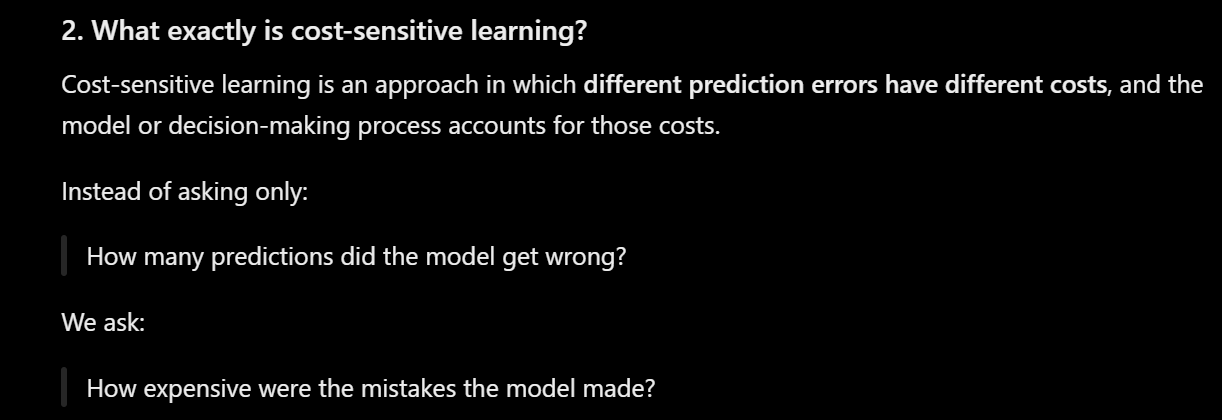

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score
)

In [10]:
sns.set_theme(style="whitegrid")

In [11]:
# Generate an imbalanced binary classification dataset
X, y = make_classification(
    n_samples=2000,
    n_features=2,
    n_informative=2,
    n_redundant=0,
    n_clusters_per_class=1,
    weights=[0.95, 0.05],
    class_sep=0.8,
    flip_y=0.01,
    random_state=42
)

df = pd.DataFrame(X, columns=["Feature 1", "Feature 2"])
df["Target"] = y

print("Dataset shape:", df.shape)
print("\nClass distribution:")
print(df["Target"].value_counts().sort_index())
print("\nClass percentages:")
print((df["Target"].value_counts(normalize=True) * 100).round(2))

Dataset shape: (2000, 3)

Class distribution:
Target
0    1893
1     107
Name: count, dtype: int64

Class percentages:
Target
0    94.65
1     5.35
Name: proportion, dtype: float64


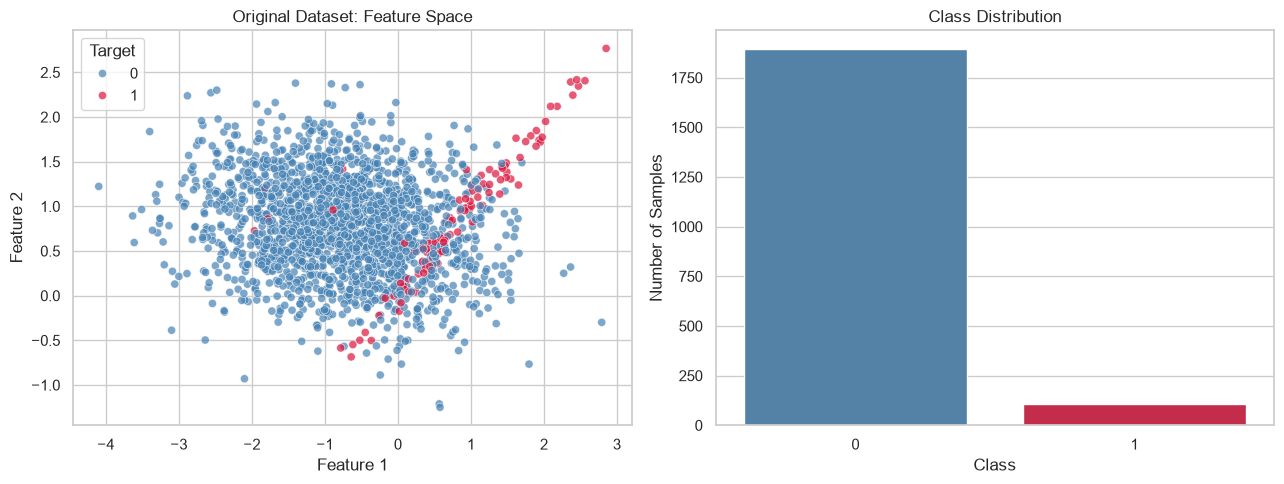

In [12]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Scatter plot
sns.scatterplot(
    data=df,
    x="Feature 1",
    y="Feature 2",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    alpha=0.7,
    s=35,
    ax=axes[0]
)
axes[0].set_title("Original Dataset: Feature Space")

# Class counts
sns.countplot(
    data=df,
    x="Target",
    hue="Target",
    palette={0: "steelblue", 1: "crimson"},
    legend=False,
    ax=axes[1]
)
axes[1].set_title("Class Distribution")
axes[1].set_xlabel("Class")
axes[1].set_ylabel("Number of Samples")

plt.tight_layout()
plt.show()

In [13]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.25,
    stratify=y,
    random_state=42
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training distribution:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest distribution:")
print(pd.Series(y_test).value_counts().sort_index())

Training distribution:
0    1420
1      80
Name: count, dtype: int64

Test distribution:
0    473
1     27
Name: count, dtype: int64


In [14]:

COST_FP = 200    # Incorrectly flagging a legitimate transaction
COST_FN = 5000   # Missing a fraudulent transaction


# Training a Baseline Model

In [15]:
model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)

y_pred = model.predict(X_test)

tn, fp, fn, tp = confusion_matrix(
    y_test, y_pred, labels=[0, 1]
).ravel()

total_cost = COST_FP * fp + COST_FN * fn

print("True Negatives:", tn)
print("False Positives:", fp)
print("False Negatives:", fn)
print("True Positives:", tp)
print("Total business cost: ₹", total_cost)
print("Average cost per transaction: ₹", total_cost / len(y_test))


True Negatives: 468
False Positives: 5
False Negatives: 25
True Positives: 2
Total business cost: ₹ 126000
Average cost per transaction: ₹ 252.0


Find a threshold that minimizes business cost.

Using the same Idea of Threshold Tuning, but instead of maximizing F1-score, we minimize total misclassification cost.

In [16]:
# Split the original training data into development and validation sets
X_subtrain, X_val, y_subtrain, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.25,
    stratify=y_train,
    random_state=42
)

cost_model = Pipeline([
    ("scaler", StandardScaler()),
    ("classifier", LogisticRegression(max_iter=1000))
])

cost_model.fit(X_subtrain, y_subtrain)

val_proba = cost_model.predict_proba(X_val)[:, 1]

thresholds = np.arange(0.05, 0.96, 0.01)
cost_results = []

for threshold in thresholds:
    val_pred = (val_proba >= threshold).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_val, val_pred, labels=[0, 1]
    ).ravel()

    total_cost = COST_FP * fp + COST_FN * fn

    cost_results.append({
        "Threshold": threshold,
        "FP": fp,
        "FN": fn,
        "Total Cost": total_cost,
        "Average Cost": total_cost / len(y_val)
    })

cost_results = pd.DataFrame(cost_results)

display(
    cost_results.sort_values("Total Cost").head(10)
)


,Threshold,FP,FN,Total Cost,Average Cost
0,0.05,57,2,21400,57.066667
4,0.09,32,3,21400,57.066667
3,0.08,34,3,21800,58.133333
2,0.07,39,3,22800,60.800000
1,0.06,50,3,25000,66.666667
6,0.11,27,5,30400,81.066667
5,0.10,29,5,30800,82.133333
10,0.15,24,6,34800,92.800000
9,0.14,25,6,35000,93.333333
7,0.12,26,6,35200,93.866667


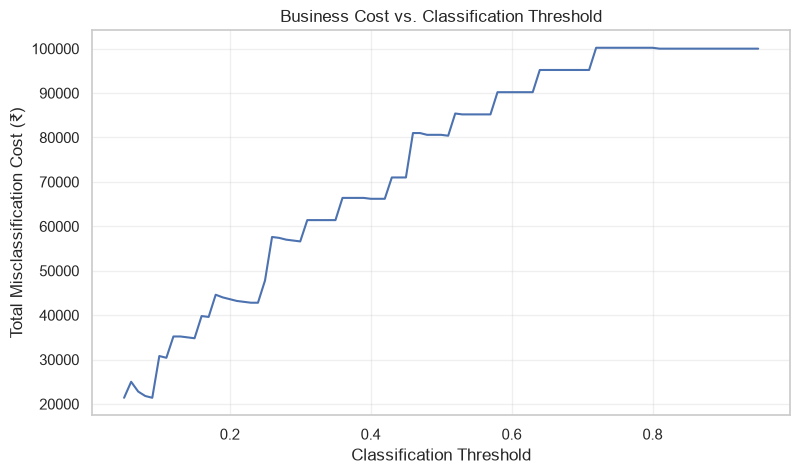

In [17]:

plt.figure(figsize=(9, 5))

plt.plot(
    cost_results["Threshold"],
    cost_results["Total Cost"]
)

plt.xlabel("Classification Threshold")
plt.ylabel("Total Misclassification Cost (₹)")
plt.title("Business Cost vs. Classification Threshold")
plt.grid(alpha=0.3)
plt.show()
